# Car Price Prediction

## 1. Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

## 2. Load Dataset

In [2]:
data_path = Path("../data/Car_Price.csv")

df = pd.read_csv(data_path)

df.head()

,Car_Name,Year,Selling_Price,Present_Price,Driven_kms,Fuel_Type,Selling_type,Transmission,Owner
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0
3,wagon r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0


## 3. Understand the Dataset

Before building the regression models, we inspect the dataset structure,
data types, descriptive statistics, and missing values.

In [3]:
print("Dataset shape:", df.shape)

print("\nDataset information:")
df.info()

print("\nDescriptive statistics:")
display(df.describe())

print("\nMissing values:")
print(df.isnull().sum())

print("\nColumn names:")
print(df.columns.tolist())

Dataset shape: (301, 9)

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 301 entries, 0 to 300
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Car_Name       301 non-null    str    
 1   Year           301 non-null    int64  
 2   Selling_Price  301 non-null    float64
 3   Present_Price  301 non-null    float64
 4   Driven_kms     301 non-null    int64  
 5   Fuel_Type      301 non-null    str    
 6   Selling_type   301 non-null    str    
 7   Transmission   301 non-null    str    
 8   Owner          301 non-null    int64  
dtypes: float64(2), int64(3), str(4)
memory usage: 21.3 KB

Descriptive statistics:


,Year,Selling_Price,Present_Price,Driven_kms,Owner
count,301.000000,301.000000,301.000000,301.000000,301.000000
mean,2013.627907,4.661296,7.628472,36947.205980,0.043189
std,2.891554,5.082812,8.642584,38886.883882,0.247915
min,2003.000000,0.100000,0.320000,500.000000,0.000000
25%,2012.000000,0.900000,1.200000,15000.000000,0.000000
50%,2014.000000,3.600000,6.400000,32000.000000,0.000000
75%,2016.000000,6.000000,9.900000,48767.000000,0.000000
max,2018.000000,35.000000,92.600000,500000.000000,3.000000



Missing values:
Car_Name         0
Year             0
Selling_Price    0
Present_Price    0
Driven_kms       0
Fuel_Type        0
Selling_type     0
Transmission     0
Owner            0
dtype: int64

Column names:
['Car_Name', 'Year', 'Selling_Price', 'Present_Price', 'Driven_kms', 'Fuel_Type', 'Selling_type', 'Transmission', 'Owner']


## 4. Exploratory Data Analysis (EDA)

Exploratory Data Analysis is used to understand the distribution of car prices
and the relationships between the available features and the selling price.

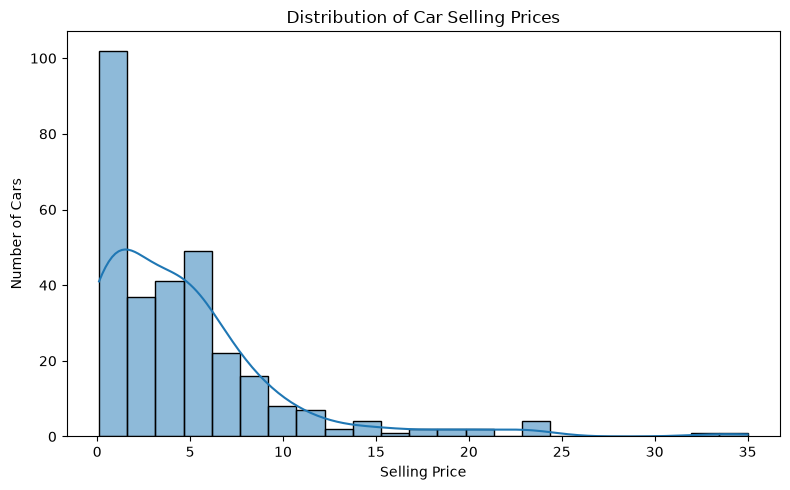

In [4]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="Selling_Price",
    kde=True
)

plt.title("Distribution of Car Selling Prices")
plt.xlabel("Selling Price")
plt.ylabel("Number of Cars")

plt.tight_layout()
plt.show()

## 5. Numerical Feature Relationships

Correlation analysis is used to examine the linear relationships between the
numerical variables in the dataset.

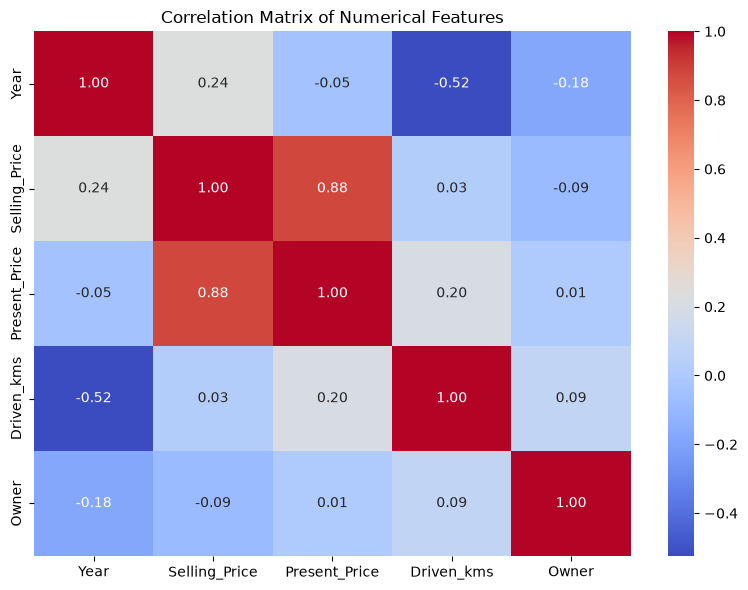

In [5]:
correlation_matrix = df[
    [
        "Year",
        "Selling_Price",
        "Present_Price",
        "Driven_kms",
        "Owner"
    ]
].corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

plt.title("Correlation Matrix of Numerical Features")

plt.tight_layout()
plt.show()

## 6. Categorical Feature Analysis

The categorical features are examined to understand the distribution of
different fuel types, selling types, and transmission types in the dataset.

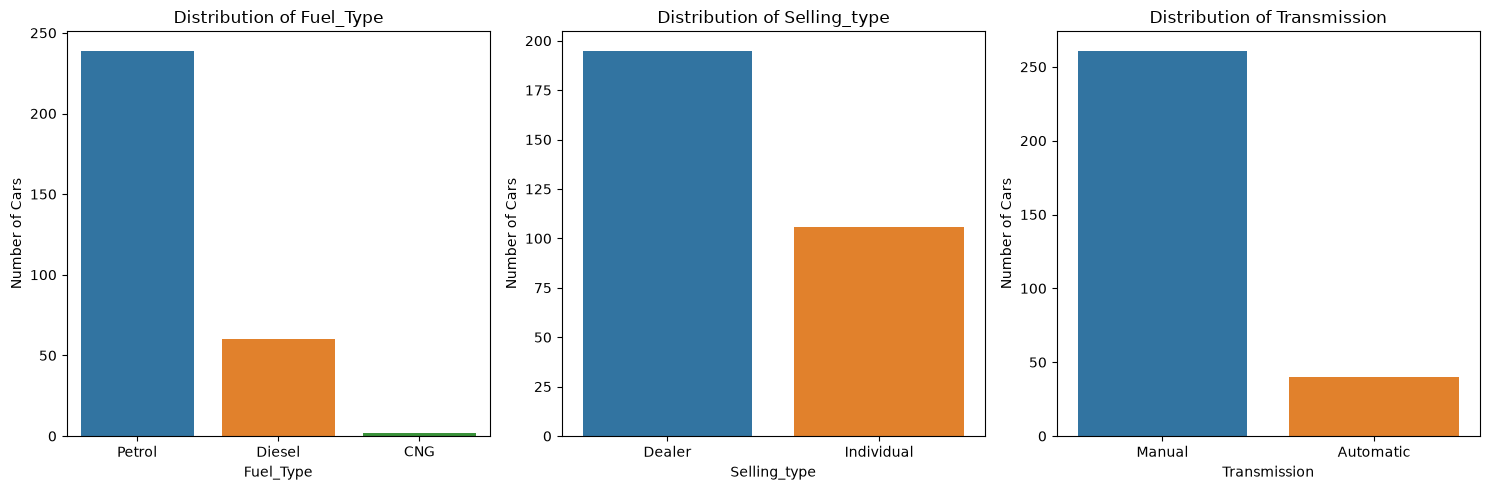

In [6]:
categorical_columns = [
    "Fuel_Type",
    "Selling_type",
    "Transmission"
]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, column in zip(axes, categorical_columns):
    sns.countplot(
        data=df,
        x=column,
        hue=column,
        legend=False,
        ax=ax
    )
    ax.set_title(f"Distribution of {column}")
    ax.set_xlabel(column)
    ax.set_ylabel("Number of Cars")

plt.tight_layout()
plt.show()

## 7. Prepare Features and Target

The `Selling_Price` column is the target variable.

The `Car_Name` column is excluded because it contains individual car names
with many unique categories.

The remaining numerical and categorical features are used as predictors.

In [7]:
X = df[
    [
        "Year",
        "Present_Price",
        "Driven_kms",
        "Fuel_Type",
        "Selling_type",
        "Transmission",
        "Owner"
    ]
]

y = df["Selling_Price"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (301, 7)
Target shape: (301,)


## 8. Split the Data into Training and Testing Sets

The dataset is divided into 80% training data and 20% testing data.

The training data is used to build the regression models, while the testing
data is used to evaluate their performance on unseen observations.

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 240
Testing samples: 61


## 9. Preprocess Categorical Features

The categorical features are converted into numerical representations using
One-Hot Encoding.

The numerical features are passed through without modification.

In [9]:
categorical_features = [
    "Fuel_Type",
    "Selling_type",
    "Transmission"
]

numerical_features = [
    "Year",
    "Present_Price",
    "Driven_kms",
    "Owner"
]

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),
        (
            "numerical",
            "passthrough",
            numerical_features
        )
    ]
)

print("Preprocessor created successfully.")

Preprocessor created successfully.


## 10. Train and Compare Regression Models

Three regression algorithms are trained and compared:

- Linear Regression
- Decision Tree Regression
- Random Forest Regression

Each model uses the same preprocessing pipeline and the same training and
testing data.

In [11]:
models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        random_state=42
    )
}

results = []

for name, model in models.items():

    pipeline = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("model", model)
        ]
    )

    pipeline.fit(X_train, y_train)

    y_pred = pipeline.predict(X_test)

    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)

    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2 Score": r2
    })

results_df = pd.DataFrame(results)

results_df

,Model,MAE,RMSE,R2 Score
0,Linear Regression,1.216374,1.865838,0.848871
1,Decision Tree,0.723443,1.121477,0.945401
2,Random Forest,0.614615,0.919290,0.963314


## 12. Actual vs Predicted Prices

The actual selling prices are compared with the prices predicted by the
Random Forest model.

Points closer to the diagonal reference line indicate predictions that are
closer to the actual values.

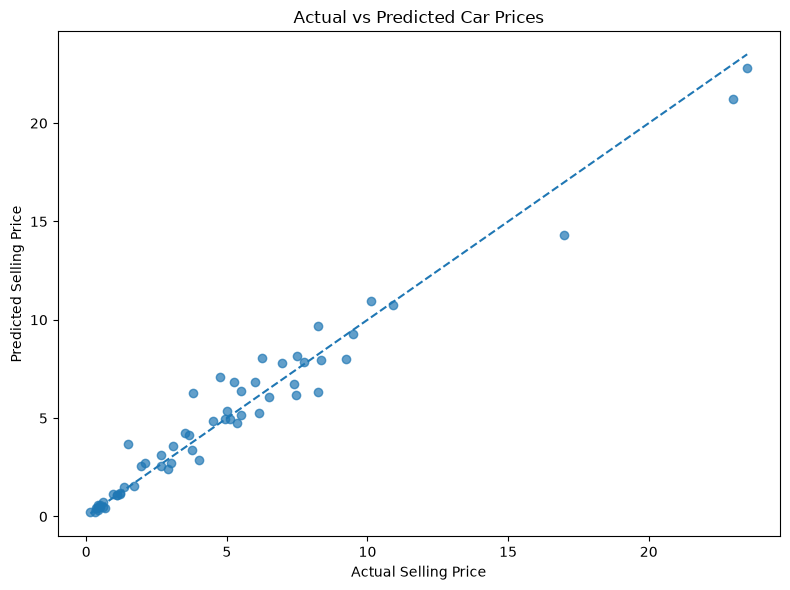

In [12]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_pred,
    alpha=0.7
)

min_price = min(y_test.min(), y_pred.min())
max_price = max(y_test.max(), y_pred.max())

plt.plot(
    [min_price, max_price],
    [min_price, max_price],
    linestyle="--"
)

plt.title("Actual vs Predicted Car Prices")
plt.xlabel("Actual Selling Price")
plt.ylabel("Predicted Selling Price")

plt.tight_layout()
plt.show()

## 13. Save Model Results

The regression model comparison results are saved as a CSV file for
documentation and further reference.

In [13]:
results_df.to_csv(
    "../results/model_comparison.csv",
    index=False
)

print("Model comparison saved successfully.")

Model comparison saved successfully.
